# Mapping Henry Ice Rise



In [1]:
# Imports for the geospatial workflow to come.
import numpy as np

import pandas as pd
import xarray as xr
import rioxarray  
import geopandas as gpd
import matplotlib.pyplot as plt
import pdemtools as pdt
import geopandas as gpd

from matplotlib.patches import Rectangle


# Load data

### Whole-HIR DEM

In [2]:
wide_bounds = [-1075132.7702415055,385691.92500027467,-814001.8660672065,576698.6831667994]

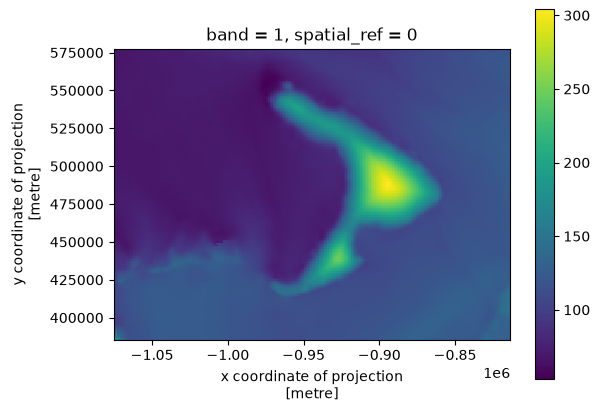

In [3]:
bm2_surf = rioxarray.open_rasterio('/Users/jkingslake/Documents/science/QGIS/Quantarctica3/TerrainModels/BEDMAP2/bedmap2_surface.tif', chunked=True).rio.clip_box(*wide_bounds)
bm2_thickness = rioxarray.open_rasterio('/Users/jkingslake/Documents/science/QGIS/Quantarctica3/TerrainModels/BEDMAP2/bedmap2_thickness.tif', chunked=True).rio.clip_box(*wide_bounds)
bm2_surf.plot()
plt.gca().set_aspect('equal') 

### MODIS Mosaic of Antarctica

/Users/jkingslake/Documents/science/QGIS/Quantarctica3/SatelliteImagery/MODIS/MODIS_Mosaic.tif  

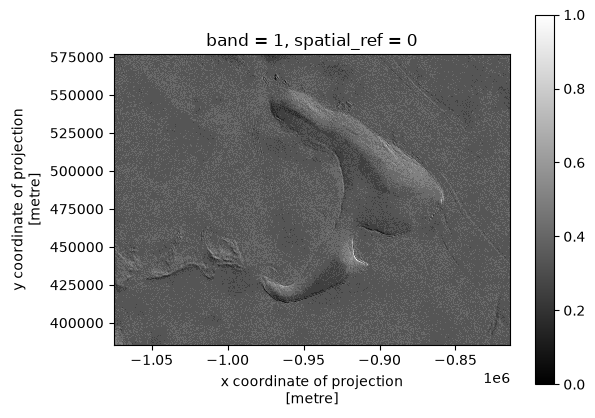

In [4]:
moa = rioxarray.open_rasterio('/Users/jkingslake/Documents/science/QGIS/Quantarctica3/SatelliteImagery/MODIS/MODIS_Mosaic.tif', chunked=True).rio.clip_box(*wide_bounds)
min_val = moa.min()
max_val = moa.max()
moa_norm = (moa - min_val) / (max_val - min_val)
moa_norm.plot(cmap = 'gray')

plt.gca().set_aspect('equal') 

In [5]:
bounds = [-1075132.7702415055,385691.92500027467,-814001.8660672065,576698.6831667994]

In [6]:
close_bounds = [-1002656.0978736078,507610.546840948,-914375.0208685583,572184.6055089663] # closer

In [7]:
dem = pdt.load.mosaic(
    dataset='rema',  # must be `arcticdem` or `rema`
    resolution=32,        # must be 2, 10, or 32
    bounds=close_bounds,        # (xmin, ymin, xmax, ymax) or a shapely geometry
)

In [8]:
dem = dem.coarsen(x=4, y=4, boundary='trim').mean()  # coarsen to 128 m

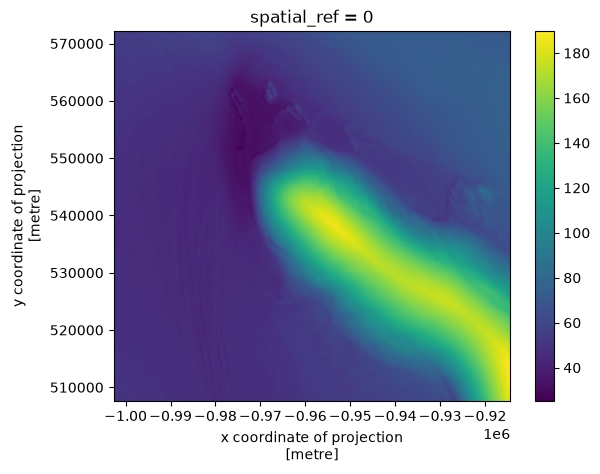

In [9]:
dem.plot()

In [10]:
moa_close = rioxarray.open_rasterio('/Users/jkingslake/Documents/science/QGIS/Quantarctica3/SatelliteImagery/MODIS/MODIS_Mosaic.tif', chunked=True).rio.clip_box(*close_bounds)
min_val = moa_close.min()
max_val = moa_close.max()
moa_norm_close = (moa_close - min_val) / (max_val - min_val)

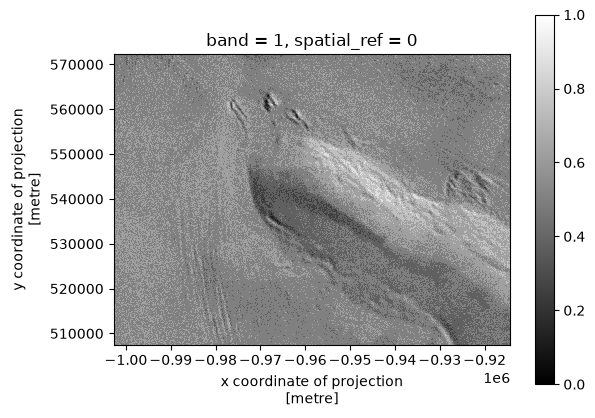

In [11]:
moa_norm_close.plot(cmap = 'gray')

plt.gca().set_aspect('equal') 

In [12]:
hillshade = dem.pdt.terrain('hillshade', )

In [13]:
HEnorth_FL5_gdf = gpd.read_file('HEnorth_FL5_gdf.geojson')
drillsite_gdf = gpd.read_file('drillsite_gdf.geojson')


<Axes: title={'center': 'spatial_ref = 0'}, xlabel='x coordinate of projection\n[metre]', ylabel='y coordinate of projection\n[metre]'>

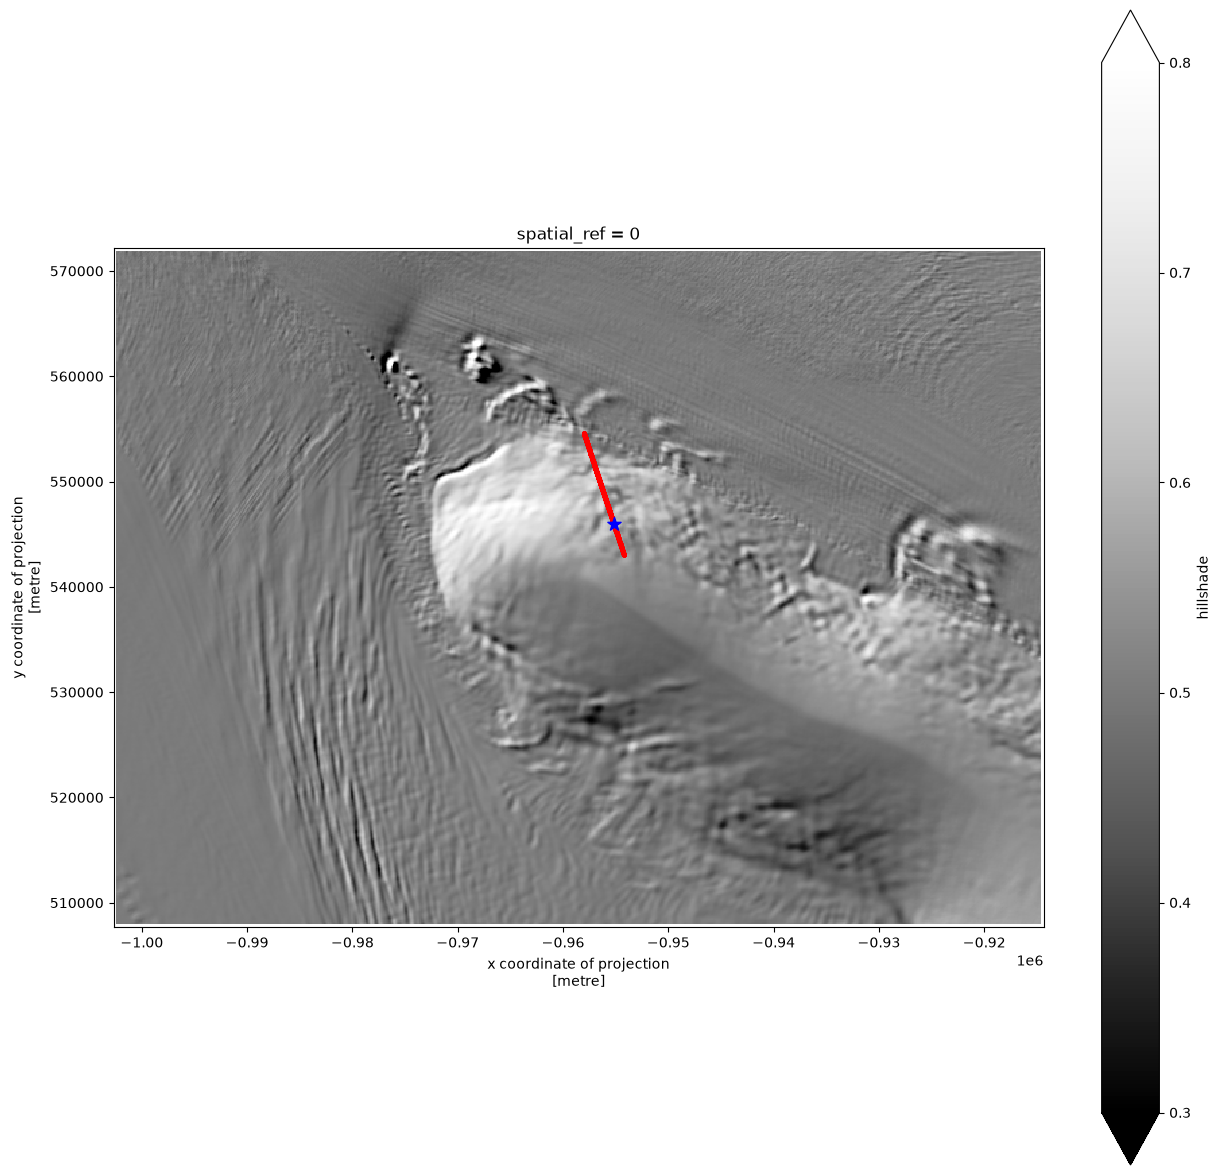

In [14]:
fig, ax = plt.subplots(figsize=(15, 15))

hillshade.plot(ax=ax,cmap='Greys_r', vmin=0.3, vmax = 0.8)
HEnorth_FL5_gdf.plot(ax=ax, color='red', markersize=5, label='HEnorth FL5')
drillsite_gdf.plot(ax=ax, marker = '*', markersize=100, color='blue', label='Drill Site')

<Axes: title={'center': 'spatial_ref = 0'}, xlabel='x coordinate of projection\n[metre]', ylabel='y coordinate of projection\n[metre]'>

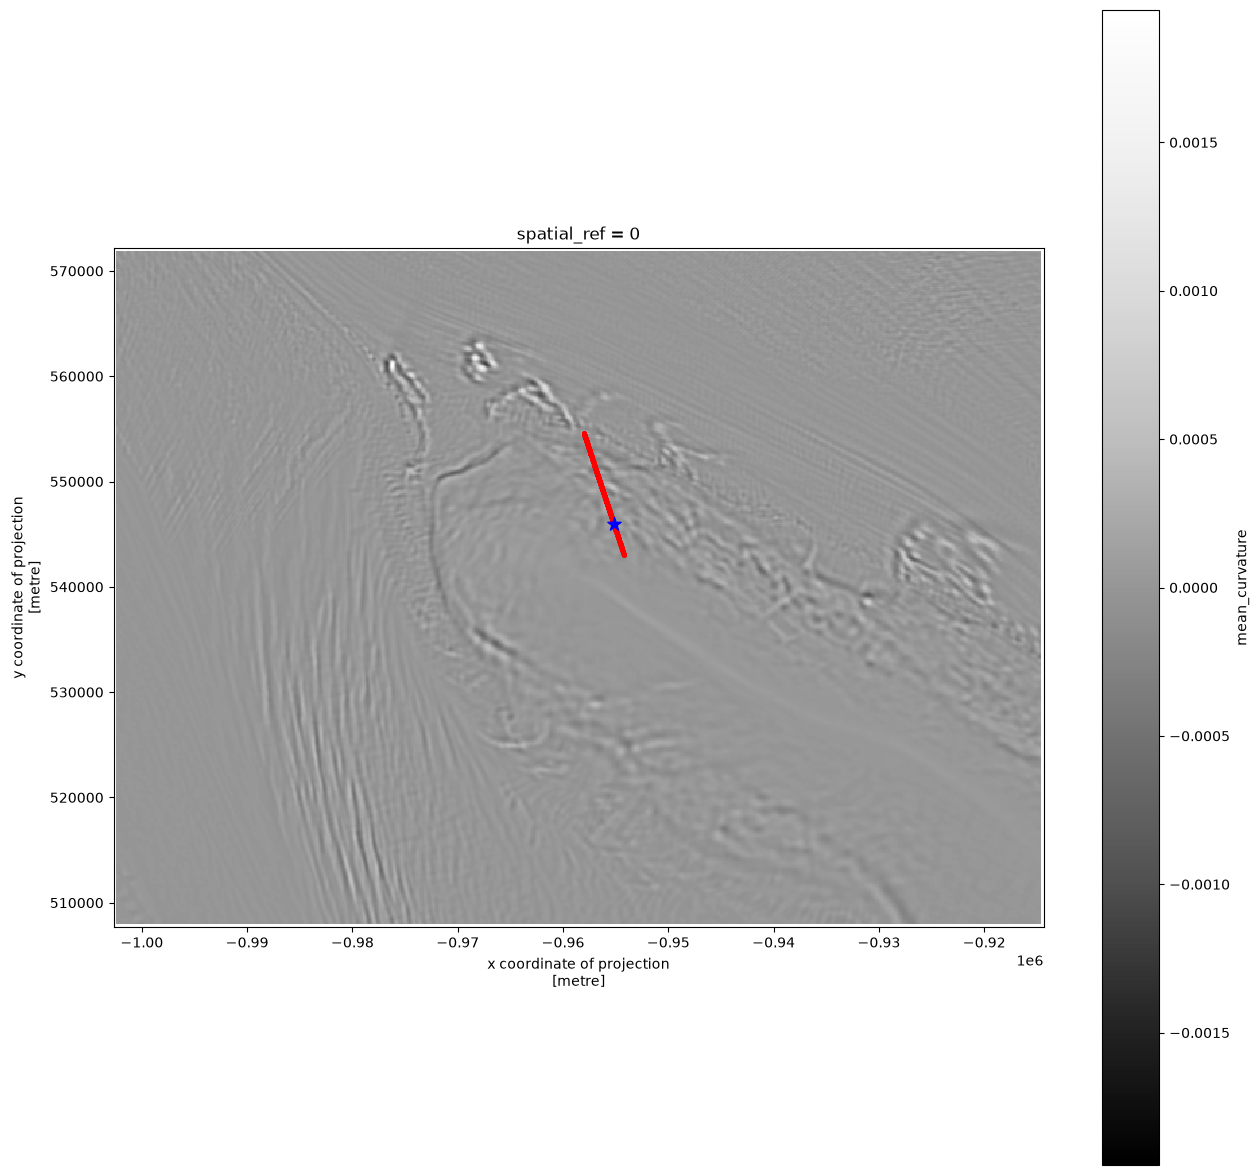

In [15]:
fig, ax = plt.subplots(figsize=(15, 15))
dem.pdt.terrain('mean_curvature', ).plot(ax=ax,cmap='Greys_r')
HEnorth_FL5_gdf.plot(ax=ax, color='red', markersize=5, label='HEnorth FL5')
drillsite_gdf.plot(ax=ax, marker = '*', markersize=100, color='blue', label='Drill Site')

In [16]:
all_del_positions = gpd.read_file('/Users/jkingslake/Documents/data/ronne_fieldwork/python_processing/delores_GPS_singleBand_both_seasons.gpkg')

In [17]:
all_del_positions_small = all_del_positions.iloc[::20].reset_index(drop=True)


In [18]:
all_del_positions_small = all_del_positions_small.to_crs('EPSG:3031')
all_del_positions_small

,lat,lon,geometry
0,-80.648548,-61.225158,POINT (-892495.682 490143.445)
1,-80.648550,-61.225162,POINT (-892495.552 490143.305)
2,-80.648548,-61.225164,POINT (-892495.731 490143.357)
3,-80.648550,-61.225167,POINT (-892495.595 490143.227)
4,-80.648550,-61.225168,POINT (-892495.609 490143.201)
...,...,...,...
78206,-79.947457,-60.420968,POINT (-952234.45 540483.605)
78207,-79.947457,-60.420968,POINT (-952234.45 540483.605)
78208,-79.947457,-60.420968,POINT (-952234.45 540483.605)
78209,-79.947457,-60.420968,POINT (-952234.45 540483.605)


In [19]:
drillsite_gdf

,geometry
0,POINT (-955191.471 545987.856)


In [20]:
ref_point = drillsite_gdf.geometry.iloc[0]
all_del_positions_small["dist_m"] = all_del_positions_small.distance(ref_point)
all_del_positions_near = all_del_positions_small[all_del_positions_small["dist_m"] < 60000]
all_del_positions_near

,lat,lon,geometry,dist_m
610,-80.178622,-61.550633,POINT (-940461.348 509553.252),39299.578585
611,-80.178623,-61.550633,POINT (-940461.189 509553.166),39299.717824
612,-80.178622,-61.550633,POINT (-940461.348 509553.252),39299.578585
613,-80.178622,-61.550633,POINT (-940461.348 509553.252),39299.578585
614,-80.178622,-61.550635,POINT (-940461.363 509553.224),39299.599145
...,...,...,...,...
78206,-79.947457,-60.420968,POINT (-952234.45 540483.605),6248.260244
78207,-79.947457,-60.420968,POINT (-952234.45 540483.605),6248.260244
78208,-79.947457,-60.420968,POINT (-952234.45 540483.605),6248.260244
78209,-79.947457,-60.420968,POINT (-952234.45 540483.605),6248.260244


<Axes: >

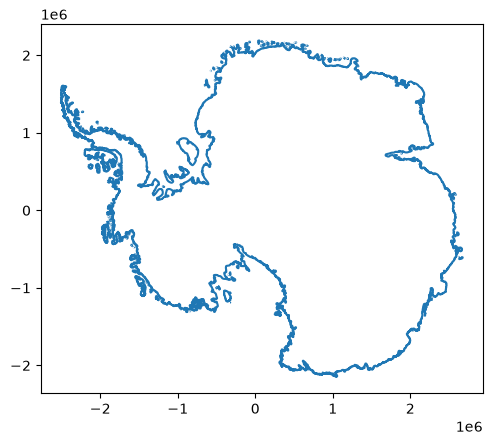

In [21]:
gl = gpd.read_file('/Users/jkingslake/Documents/science/QGIS/Quantarctica3/Glaciology/MEaSUREs Antarctic Boundaries/GroundingLine_Antarctica_v2.shp')
gl.boundary.plot()


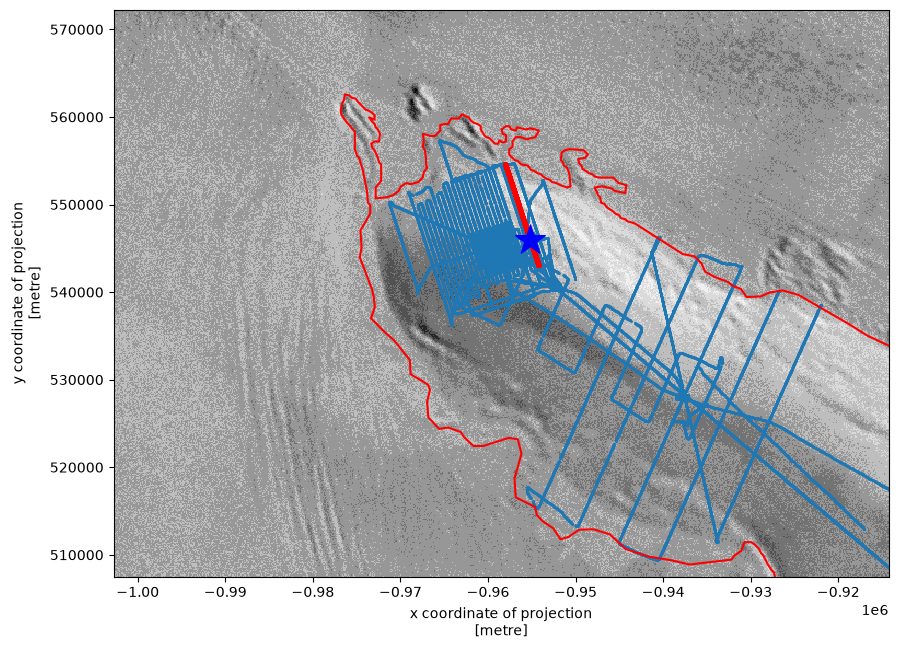

In [22]:
fig, ax = plt.subplots(figsize=(10, 10))
moa_close.plot(ax=ax,cmap='Greys_r', add_colorbar = False)
gl.boundary.plot(ax=ax, color='red', label = 'grounding line')

all_del_positions_near.plot(ax=ax, markersize=1,)
HEnorth_FL5_gdf.plot(ax=ax, color='red', markersize=5, label='HEnorth FL5')
drillsite_gdf.plot(ax=ax, marker = '*', markersize=500, color='blue', label='Drill Site')
ax.set_title('')

plt.savefig('radarline_location_map.png', dpi = 300, bbox_inches='tight'  )

<Axes: title={'center': 'band = 1, spatial_ref = 0'}, xlabel='x coordinate of projection\n[metre]', ylabel='y coordinate of projection\n[metre]'>

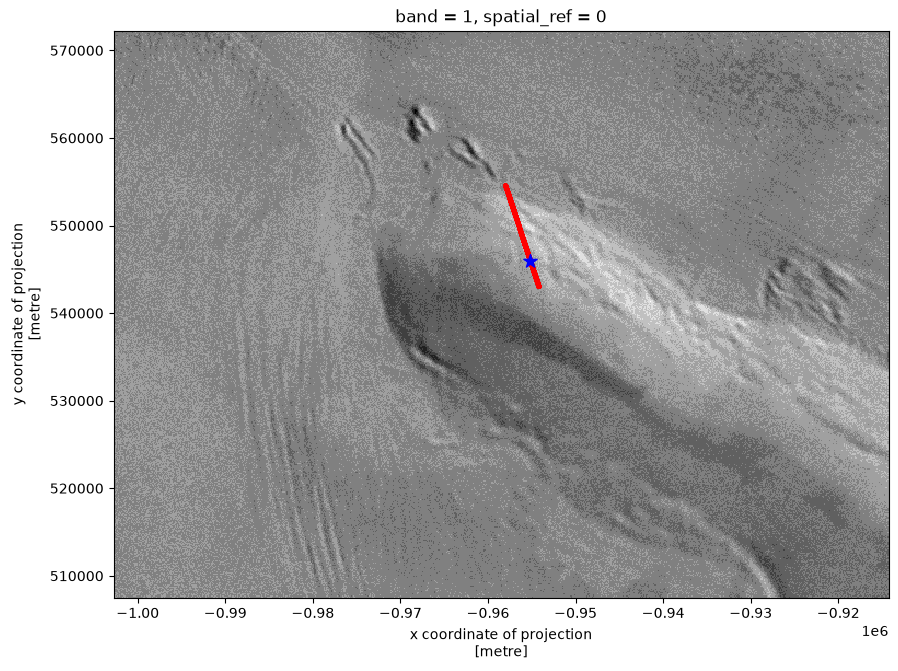

In [23]:
fig, ax = plt.subplots(figsize=(10, 10))
moa_norm_close.plot(ax=ax, cmap = 'gray',add_colorbar=False)
HEnorth_FL5_gdf.plot(ax=ax, color='red', markersize=5, label='HEnorth FL5')
drillsite_gdf.plot(ax=ax, marker = '*', markersize=100, color='blue', label='Drill Site')

In [24]:
width = 1000
height = 1000
xmin = -951368
xmax = xmin + width
ymin = 551293
ymax = ymin + height
crevasses_bounds = [xmin, ymin, xmax, ymax]
WV_crevasses= rioxarray.open_rasterio('/Users/jkingslake/Documents/projects/proposals/other/PHIRE/proposal/fridge_1479_jkingslake/ortho/WV01_20250228140506_102001010D9E6800_25FEB28140506-P1BS-509390623020_01_P007_u08rf3031.tif', chunks = True, masked = True)\
    .rio.clip_box(*crevasses_bounds)

In [25]:
WV_close = rioxarray.open_rasterio('/Users/jkingslake/Documents/projects/proposals/other/PHIRE/proposal/fridge_1479_jkingslake/ortho/WV01_20250228140506_102001010D9E6800_25FEB28140506-P1BS-509390623020_01_P007_u08rf3031.tif', chunks = True, masked = True)\
    .rio.clip_box(*close_bounds).coarsen(x=20, y=20, boundary = 'trim').mean().compute()

In [26]:
drillsite_x = drillsite_gdf.get_geometry(0).x.values[0]
drillsite_y = drillsite_gdf.get_geometry(0).y.values[0]
width = 1000
height = 1000
xmin = -951368
xmax = xmin + width
ymin = 551293
ymax = ymin + height
drillsite_bounds = [drillsite_x-width/2, drillsite_y-height/2, drillsite_x+width/2, drillsite_y+height/2]
WV_drillsite = rioxarray.open_rasterio('/Users/jkingslake/Documents/projects/proposals/other/PHIRE/proposal/fridge_1479_jkingslake/ortho/WV01_20250228140506_102001010D9E6800_25FEB28140506-P1BS-509390623020_01_P007_u08rf3031.tif', chunks = True, masked = True)\
    .rio.clip_box(*drillsite_bounds)


In [27]:
drillsite_bounds[1]-drillsite_bounds[0]

np.float64(1501179.3269870002)

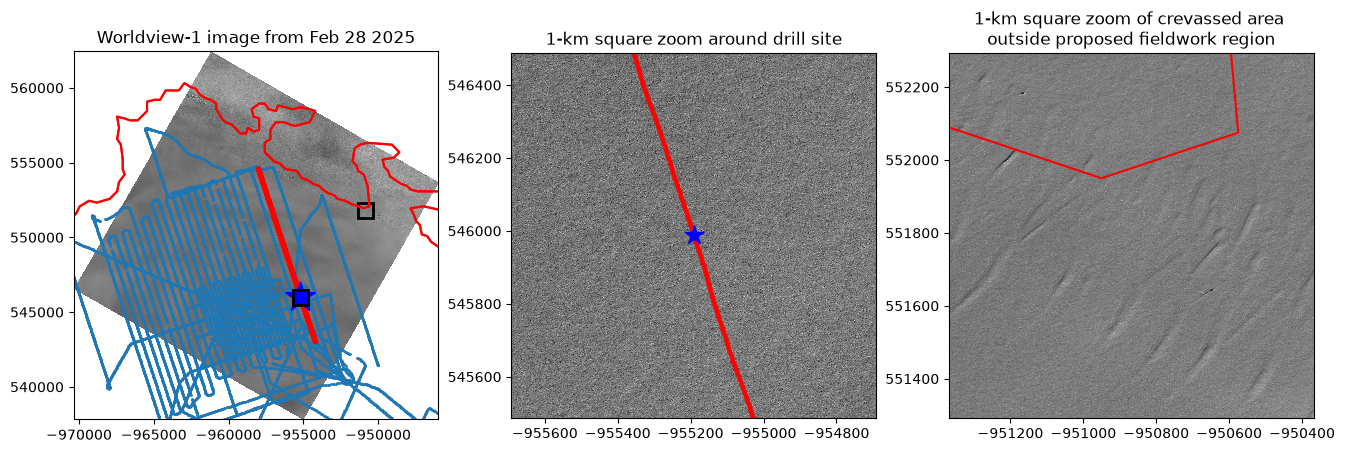

In [32]:
fig, ax = plt.subplots(1,3, figsize = (16, 8),)
WV_close.plot(ax=ax[0], cmap = 'gray', add_colorbar=False)
gl.boundary.plot(ax=ax[0], color='red', label = 'grounding line')

all_del_positions_near.plot(ax=ax[0], markersize=1,)
HEnorth_FL5_gdf.plot(ax=ax[0], color='red', markersize=5, label='HEnorth FL5')
drillsite_gdf.plot(ax=ax[0], marker = '*', markersize=500, color='blue', label='Drill Site')
# HEnorth_FL5_gdf.plot(ax=ax[0], color='red', markersize=5, label='radar line')
# drillsite_gdf.plot(ax=ax[0], marker = '*', markersize=200, color='blue', label='Drill Site')
ax[0].set_ylabel('')
ax[0].set_xlabel('')
gl.boundary.plot(ax=ax[0], color='red', label = 'grounding line')

rect1 = Rectangle(
    (drillsite_bounds[0], drillsite_bounds[1]),      # bottom-left corner, in data coordinates (distance, z)
    width,     # extent along x
    height,     # extent along y
    linewidth=2,
    edgecolor="black",
    facecolor="none",
)
ax[0].add_patch(rect1)

rect2 = Rectangle(
    (crevasses_bounds[0], crevasses_bounds[1]),      # bottom-left corner, in data coordinates (distance, z)
    width,     # extent along x
    height,     # extent along y
    linewidth=2,
    edgecolor="black",
    facecolor="none",
)
ax[0].add_patch(rect2)
ax[0].set_title('Worldview-1 image from Feb 28 2025')
# ax[0].legend()


WV_drillsite.plot(ax=ax[1], cmap = 'gray', add_colorbar=False)
HEnorth_FL5_gdf.plot(ax=ax[1], color='red', markersize=5, label='radar line')
drillsite_gdf.plot(ax=ax[1], marker = '*', markersize=200, color='blue', label='Drill Site')
ax[1].set_ylabel('')
ax[1].set_xlabel('')
ax[1].set_title('1-km square zoom around drill site')


WV_crevasses.plot(ax=ax[2], cmap = 'gray', add_colorbar=False)
HEnorth_FL5_gdf.plot(ax=ax[2], color='red', markersize=5, label='HEnorth FL5')
drillsite_gdf.plot(ax=ax[2], marker = '*', markersize=100, color='blue', label='Drill Site')
ax[2].set_ylabel('')
ax[2].set_xlabel('')
ax[2].set_title('1-km square zoom of crevassed area \n outside proposed fieldwork region ')
gl.boundary.plot(ax=ax[2], color='red', label = 'grounding line')

plt.savefig('worldview_crevasse_imagery_1.png', dpi = 300, bbox_inches='tight'  )
